In [1]:
import json, re, threading, time, warnings
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import requests
import sep
import matplotlib.pyplot as plt
from matplotlib.path import Path as MplPath
import astropy.units as u
from astropy import log
from astropy.coordinates import SkyCoord, Distance
from astropy.io import fits
from astropy.io.fits.hdu.compressed._codecs import Rice1
from astropy.stats import sigma_clipped_stats
from astropy.table import Table, vstack, unique
from astropy.time import Time
from astropy.timeseries import LombScargle
from astropy.wcs import WCS
from astroquery.ipac.irsa import Irsa
from photutils.aperture import CircularAperture, CircularAnnulus
from pyvo.dal import DALServiceError

from app.config import get_settings

cfg = get_settings()
log.setLevel("WARNING")
warnings.simplefilter("ignore")

N_PIX = 2040
ROW_BYTES = N_PIX * 4
HALF_ROWS = 150                # read target row ± 150: comparison stars within ~148 px (~15') are in every frame
R_AP, R_IN, R_OUT = 2.5, 6, 10  # aperture and background annulus [pixels]
PSF_SIGMA = 0.75               # Gaussian approximation of the effective PSF (FWHM ~1.5 px)
MAX_LOST = 0.20                # drop a measurement if > 20 % of the star's light falls on bad pixels
MIN_COMP_SNR = 20              # comparison stars used as the "constant star" reference
WING_IN, WING_OUT = 9, 14      # saturated stars: measure the PSF wings outside the flagged core [pixels]
FAR_IN, FAR_OUT = 20, 28       # background for the wing measurement [pixels]
EXCLUDE = ["SUR_ERROR", "NONFUNC", "MISSING_DATA", "HOT", "COLD", "NONLINEAR",
           "PERSIST", "BLOOM", "SNOWBALL", "HALO", "SATELLITE_HALO"]   # official recipe for photometry
DATA_DIR = Path("../../../data")   # repo /data/ is git-ignored
CAL_DIR = DATA_DIR / "calibration"
session = requests.Session()


In [2]:
def get_bytes(url, start, end, tries=4):
    for i in range(tries):
        try:
            r = session.get(url, headers={"Range": f"bytes={start}-{end}"}, timeout=60)
            r.raise_for_status()
            return r.content
        except requests.RequestException:
            if i == tries - 1:
                raise
            time.sleep(1 + i)


def read_header(raw, start=0):
    """FITS header starting at byte `start` of `raw` -> (header, offset right after it)."""
    i = start
    while i + 2880 <= len(raw):
        block = raw[i:i + 2880]
        if any(block[k:k + 3] == b"END" and not block[k + 3:k + 80].strip() for k in range(0, 2880, 80)):
            return fits.Header.fromstring(raw[start:i + 2880]), i + 2880
        i += 2880
    raise ValueError("FITS header longer than the bytes read")


CAL_FILES = {
    "swcs": "dr1/spectral_wcs/cal-swcs-v5-2026-191/{d}/spectral_wcs_D{d}_spx_cal-swcs-v5-2026-191.fits",
    "sapm": "dr1/solid_angle_pixel_map/cal-sapm-v3-2026-191/{d}/solid_angle_pixel_map_D{d}_spx_cal-sapm-v3-2026-191.fits",
}
CAL = {}
CAL_LOCK = threading.Lock()
def calibration(det):
    """Per-pixel λ (CWAVE), bandwidth (CBAND) and pixel solid angle for one detector.
    Downloaded once to data/calibration (~50 MB per detector), then memory-mapped."""
    with CAL_LOCK:
        return _calibration(det)


def _calibration(det):
    if det not in CAL:
        CAL_DIR.mkdir(parents=True, exist_ok=True)
        files = {}
        for kind, path in CAL_FILES.items():
            local = CAL_DIR / Path(path.format(d=det)).name
            if not local.exists():
                tmp = local.with_suffix(".part")
                tmp.write_bytes(requests.get(cfg.s3_https_base + path.format(d=det), timeout=300).content)
                tmp.replace(local)
            files[kind] = fits.open(local, memmap=True)
        CAL[det] = dict(lam=files["swcs"]["CWAVE"].data, bw=files["swcs"]["CBAND"].data,
                        omega=files["sapm"]["IMAGE"].data)
    return CAL[det]


def resolve(name):
    """Position + proper motion from Sesame (CDS)."""
    xml = requests.get(cfg.sesame_url + requests.utils.quote(name), timeout=30).text
    val = lambda p: (m := re.search(p, xml, re.S)) and float(m.group(1))
    ra, dec = val(r"<jradeg>([-\d.eE+]+)"), val(r"<jdedeg>([-\d.eE+]+)")
    if ra is None:
        raise ValueError(f"Sesame could not resolve {name!r}")
    pmra, pmdec, plx = val(r"<pmRA>([-\d.eE+]+)") or 0.0, val(r"<pmDE>([-\d.eE+]+)") or 0.0, val(r"<plx>\s*<v>([-\d.eE+]+)")
    return SkyCoord(ra * u.deg, dec * u.deg, pm_ra_cosdec=pmra * u.mas / u.yr, pm_dec=pmdec * u.mas / u.yr,
                    distance=Distance(parallax=plx * u.mas) if plx and plx > 0 else 1 * u.kpc, obstime=Time("J2000"))


def at_epoch(star, mjd):
    return star.apply_space_motion(new_obstime=Time(mjd, format="mjd"))


def query_sia(pos, collection, tries=6):
    for i in range(tries):
        try:
            return Irsa.query_sia(pos=(pos, 0.01 * u.deg), collection=collection)
        except DALServiceError:
            time.sleep(2 * (i + 1))
    raise RuntimeError(f"IRSA SIA failed {tries} times for {collection}")


def contains(s_region, c):
    p = np.array(re.findall(r"[-+]?\d+\.?\d*(?:[eE][-+]?\d+)?", str(s_region)), float).reshape(-1, 2)
    q = np.c_[(p[:, 0] - c.ra.deg) * np.cos(c.dec.rad), p[:, 1] - c.dec.deg]
    return MplPath(q).contains_point((0, 0))


for _d in range(1, 7):      # download / open the 12 calibration files once (~300 MB, ~1 min the first time)
    calibration(_d)


def find_frames(star):
    """Every DR1 + QR3 frame (wide and deep surveys) whose footprint contains the target."""
    here = at_epoch(star, 61050)
    pos = SkyCoord(here.ra, here.dec)
    tabs = [query_sia(pos, c) for c in cfg.sia_collections + cfg.sia_deep_collections]
    t = vstack([x for x in tabs if len(x)])
    t = unique(t, keys="access_url")
    t = t[[contains(r["s_region"], here) for r in t]]
    t.sort("t_min")
    t["pass_id"] = np.r_[0, np.cumsum(np.diff(t["t_min"]) > 100)]   # passes are ~6 months apart
    return t


In [3]:
def read_frame(row, star):
    url = cfg.s3_https_base + json.loads(row["cloud_access"])["aws"]["key"]
    det = int(str(row["energy_bandpassname"])[-1])
    raw = get_bytes(url, 0, 20 * 2880 - 1)
    _, image_hdr = read_header(raw, 0)
    hh, data0 = read_header(raw, image_hdr)
    wcs = WCS(hh)
    x, y = map(float, wcs.world_to_pixel(at_epoch(star, hh["MJD-AVG"])))
    r0, r1 = max(0, int(y) - HALF_ROWS), min(N_PIX, int(y) + HALF_ROWS + 1)
    img = np.frombuffer(get_bytes(url, data0 + r0 * ROW_BYTES, data0 + r1 * ROW_BYTES - 1), ">f4")
    img = img.reshape(r1 - r0, N_PIX).astype(float)

    flags_hdr0 = data0 + N_PIX * ROW_BYTES                       # FLAGS starts right after IMAGE (fixed size)
    raw = get_bytes(url, flags_hdr0, flags_hdr0 + 20 * 2880 + N_PIX * 8 - 1)
    fh, table0 = read_header(raw, 0)
    desc = np.frombuffer(raw[table0:table0 + N_PIX * 8], ">i4").reshape(N_PIX, 2)   # (nbytes, heap offset) per row
    heap0 = flags_hdr0 + table0 + N_PIX * 8
    lo, hi = desc[r0:r1, 1].min(), (desc[r0:r1, 1] + desc[r0:r1, 0]).max()
    heap = get_bytes(url, heap0 + lo, heap0 + hi - 1)
    codec = Rice1(blocksize=fh["ZVAL1"], bytepix=fh["ZVAL2"], tilesize=N_PIX)
    flags = np.stack([np.asarray(codec.decode(np.frombuffer(heap[o - lo:o - lo + n], np.uint8))).view("i4")[:N_PIX]
                      for n, o in desc[r0:r1]])
    masks = {fh[f"MSKN{k[4:]}"]: int(fh[k]) for k in fh if k.startswith("MSKM")}
    return dict(url=url, det=det, mjd=hh["MJD-AVG"], pass_id=int(row["pass_id"]), wcs=wcs, x=x, y=y,
                r0=r0, img=img, flags=flags, masks=masks)


def photometry(fr, x, y):
    """Aperture flux [mJy] at detector pixel (x, y) + λ, bandwidth. Bad pixels (official recipe) are left out and
    the flux is corrected for the light they would have had; NaN if more than MAX_LOST of the light is lost."""
    yl = y - fr["r0"]
    if not (R_OUT + 1 <= x < N_PIX - R_OUT - 1 and R_OUT + 1 <= yl < fr["img"].shape[0] - R_OUT - 1):
        return None
    c0, rr0 = int(x) - R_OUT - 1, int(yl) - R_OUT - 1
    img = fr["img"][rr0:rr0 + 2 * R_OUT + 3, c0:c0 + 2 * R_OUT + 3]
    fl = fr["flags"][rr0:rr0 + 2 * R_OUT + 3, c0:c0 + 2 * R_OUT + 3]
    bad = ((fl & sum(fr["masks"].get(n, 0) for n in EXCLUDE)) != 0) | ~np.isfinite(img)
    pos = (x - c0, yl - rr0)
    ap = CircularAperture(pos, R_AP).to_mask("exact")
    in_ap = ap.to_image(img.shape)
    ring = CircularAnnulus(pos, R_IN, R_OUT).to_mask("center").to_image(img.shape) > 0
    vals = img[ring & ~bad]
    if len(vals) < 15:
        return None
    _, bkg, bkg_std = sigma_clipped_stats(vals, sigma=3.0)
    yy, xx = np.mgrid[:img.shape[0], :img.shape[1]]
    psf = np.exp(-((xx - pos[0]) ** 2 + (yy - pos[1]) ** 2) / (2 * PSF_SIGMA**2)) * in_ap
    lost = float(psf[bad].sum() / psf.sum())             # fraction of the star's light on bad pixels
    n_bad = int(((in_ap > 0) & bad).sum())
    s = float(np.sum(np.where(bad, 0.0, img - bkg) * in_ap)) / (1 - lost) if lost < 1 else np.nan
    cal = calibration(fr["det"])
    yi, xi = int(round(y)), int(round(x))
    to_mjy = float(cal["omega"][yi, xi]) * (u.arcsec**2).to(u.sr) * 1e9
    return dict(lambda_um=float(cal["lam"][yi, xi]), bandwidth_um=float(cal["bw"][yi, xi]),
                flux_mjy=s * to_mjy if lost <= MAX_LOST else np.nan,
                err_bkg_mjy=float(np.sqrt(in_ap.sum()) * bkg_std * to_mjy), n_bad=n_bad, lost=lost,
                peak_mjysr=float(np.nanmax(img[in_ap > 0])))


def wing_photometry(fr, x, y):
    """Saturated stars: median surface brightness of the PSF wings (WING_IN-WING_OUT px), background-subtracted.
    At a fixed λ it is proportional to the star's flux, so ratios between epochs measure variability
    (relative units, not mJy)."""
    yl = y - fr["r0"]
    R = FAR_OUT + 1
    if not (R <= x < N_PIX - R and R <= yl < fr["img"].shape[0] - R):
        return np.nan
    c0, rr0 = int(x) - R, int(yl) - R
    img = fr["img"][rr0:rr0 + 2 * R + 1, c0:c0 + 2 * R + 1]
    fl = fr["flags"][rr0:rr0 + 2 * R + 1, c0:c0 + 2 * R + 1]
    bad = ((fl & sum(fr["masks"].get(n, 0) for n in EXCLUDE)) != 0) | ~np.isfinite(img)
    yy, xx = np.mgrid[:img.shape[0], :img.shape[1]]
    rad = np.hypot(xx - (x - c0), yy - (yl - rr0))
    wing = img[(rad >= WING_IN) & (rad < WING_OUT) & ~bad]
    far = img[(rad >= FAR_IN) & (rad < FAR_OUT) & ~bad]
    if len(wing) < 20 or len(far) < 30:
        return np.nan
    return float(np.median(wing) - sigma_clipped_stats(far, sigma=3.0)[1])


In [4]:
def find_comparisons(t, star, n_sample=30, max_comps=40):
    """Stars detected (sep, 10σ) within ~15' of the target in at least half of 30 sample frames, isolated."""
    rows = t[np.linspace(0, len(t) - 1, min(n_sample, len(t))).astype(int)]
    with ThreadPoolExecutor(8) as ex:
        frames = list(ex.map(lambda r: read_frame(r, star), rows))
    found = []
    for fr in frames:
        yl = fr["y"] - fr["r0"]
        R = HALF_ROWS - 2
        c0, rr0 = max(0, int(fr["x"]) - R), max(0, int(yl) - R)
        cut = np.ascontiguousarray(fr["img"][rr0:rr0 + 2 * R + 1, c0:c0 + 2 * R + 1])
        cut = np.nan_to_num(cut, nan=np.nanmedian(cut))
        bkg = sep.Background(cut, bw=32, bh=32)
        objs = sep.extract(cut - bkg.back(), 10, err=bkg.globalrms, minarea=3)
        for o in objs:
            sky = fr["wcs"].pixel_to_world(o["x"] + c0, o["y"] + rr0 + fr["r0"])
            found.append((sky.ra.deg, sky.dec.deg, o["flux"]))
    if not found:
        return SkyCoord([], [], unit="deg")
    f = np.array(found)
    pts = SkyCoord(f[:, 0], f[:, 1], unit="deg")
    groups, used = [], np.zeros(len(pts), bool)
    for i in np.argsort(-f[:, 2]):                       # brightest first
        if used[i]:
            continue
        m = (pts.separation(pts[i]).arcsec < 5) & ~used
        used |= m
        groups.append((f[m, 0].mean(), f[m, 1].mean(), m.sum(), np.median(f[m, 2])))
    g = np.array(groups)
    centers = SkyCoord(g[:, 0], g[:, 1], unit="deg")
    target = at_epoch(star, float(np.median(t["t_min"])))
    target = SkyCoord(target.ra, target.dec)
    keep = (g[:, 2] >= 0.5 * len(frames)) & (centers.separation(target).arcsec > 25) \
        & (centers.separation(target).arcsec < (HALF_ROWS - 12) * 6.15)
    for i in np.where(keep)[0]:                         # isolated: no other detected source within 30"
        others = centers.separation(centers[i]).arcsec
        if np.sum((others > 0) & (others < 30)) > 0:
            keep[i] = False
    idx = np.where(keep)[0][np.argsort(-g[keep, 3])][:max_comps]
    return centers[idx]


In [5]:
def measure_all(t, star, comps):
    def one(row):
        try:
            fr = read_frame(row, star)
        except Exception as e:                           # a broken file must not stop the run
            return [dict(error=repr(e)[:100])]
        out = []
        cx, cy = fr["wcs"].world_to_pixel(comps) if len(comps) else ([], [])
        for src, (x, y) in enumerate([(fr["x"], fr["y"])] + list(zip(np.atleast_1d(cx), np.atleast_1d(cy)))):
            p = photometry(fr, float(x), float(y))
            if p:
                p["wing_mjysr"] = wing_photometry(fr, float(x), float(y)) if src == 0 else np.nan
                out.append(dict(src=src, mjd=fr["mjd"], pass_id=fr["pass_id"], detector=fr["det"], **p))
        return out
    t0 = time.time()
    with ThreadPoolExecutor(8) as ex:
        res = [r for rs in ex.map(one, t) for r in rs]
    errors = [r for r in res if "error" in r]
    tab = Table(rows=[r for r in res if "error" not in r])
    print(f"{len(t)} frames, {len(errors)} unreadable, {len(tab)} measurements in {time.time() - t0:.0f} s")
    return tab


In [6]:
def expected(lam, flux, bw):
    """Each measurement's expected flux from the same star's OTHER measurements within ±½ bandwidth."""
    e = np.full(len(lam), np.nan)
    for i in range(len(lam)):
        near = (np.abs(lam - lam[i]) < 0.5 * bw[i]) & np.isfinite(flux)
        near[i] = False                                    # leave-one-out
        if near.sum() >= 2:
            e[i] = np.median(flux[near])
    return e


def robust_std(x):
    x = np.asarray(x, float); x = x[np.isfinite(x)]
    return 1.4826 * np.median(np.abs(x - np.median(x))) if len(x) > 2 else np.nan


def use_wings(m):
    """Saturated target: replace its aperture flux by the wing brightness (relative units)."""
    m = m.copy()
    k = m["src"] == 0
    m["flux_mjy"][k] = m["wing_mjysr"][k]
    return m


def residuals(m):
    """flux / (same star at the same λ in the other frames). Constant star -> ~1 everywhere."""
    m = m.copy()
    m["resid"] = np.nan
    for s in np.unique(m["src"]):
        k = m["src"] == s
        e = expected(np.array(m["lambda_um"][k]), np.array(m["flux_mjy"][k]), np.array(m["bandwidth_um"][k]))
        m["resid"][k] = np.array(m["flux_mjy"][k]) / e
    return m


def zero_point_check(m):
    """Is there a frame-to-frame calibration error larger than the comparison-star noise?"""
    cp = m[(m["src"] > 0) & np.isfinite(m["resid"]) & (m["flux_mjy"] > MIN_COMP_SNR * m["err_bkg_mjy"])]
    zp, n = [], []
    keys = np.unique(np.c_[np.array(cp["mjd"]), np.array(cp["detector"])], axis=0)
    for mjd, det in keys:
        g = np.array(cp["resid"][(cp["mjd"] == mjd) & (cp["detector"] == det)])
        if len(g) >= 3:
            zp.append(np.median(g)); n.append(len(g))
    noise = np.nanmedian([robust_std(cp["resid"][cp["src"] == s]) for s in np.unique(cp["src"])])
    expect = 1.25 * noise / np.sqrt(np.median(n))         # 1.25: noise of a median
    real = np.sqrt(max(robust_std(zp) ** 2 - expect ** 2, 0))
    print(f"   frame zero point: scatter {100 * robust_std(zp):.2f} %, expected from noise {100 * expect:.2f} % "
          f"-> real calibration error ~{100 * real:.2f} % per frame ({len(zp)} frames, {np.median(n):.0f} stars each)")


def summary(m, name):
    tg, cp = m[(m["src"] == 0) & np.isfinite(m["resid"])], m[(m["src"] > 0) & np.isfinite(m["resid"])]
    bright = cp["flux_mjy"] > MIN_COMP_SNR * cp["err_bkg_mjy"]
    print(f"\n== {name}: {len(tg)} target measurements with a same-λ reference, {len(np.unique(cp['src']))} comparison stars")
    print(f"   scatter: target {100 * robust_std(tg['resid']):.1f} %   |   comparison stars (S/N>{MIN_COMP_SNR}) "
          f"{100 * np.nanmedian([robust_std(cp['resid'][bright & (cp['src'] == s)]) for s in np.unique(cp['src'])]):.1f} %")
    zero_point_check(m)
    for p in np.unique(m["pass_id"]):
        c = np.array(tg["resid"][tg["pass_id"] == p]); q = np.array(cp["resid"][(cp["pass_id"] == p) & bright])
        if len(c) > 2:
            print(f"   pass {p}: target {np.median(c):.3f} ± {1.25 * robust_std(c) / np.sqrt(len(c)):.3f} (n={len(c)})"
                  f"   comparison stars {np.median(q):.3f}")


def plot(m, name):
    tg = m[(m["src"] == 0) & np.isfinite(m["flux_mjy"])]
    cp = m[(m["src"] > 0) & np.isfinite(m["resid"]) & (m["flux_mjy"] > MIN_COMP_SNR * m["err_bkg_mjy"])]
    fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
    for p in np.unique(tg["pass_id"]):
        g = tg[tg["pass_id"] == p]
        ax[0].plot(g["lambda_um"], g["flux_mjy"], ".", ms=4, label=f"pass {p} (MJD {g['mjd'].min():.0f}–{g['mjd'].max():.0f})")
    ax[0].set_yscale("log"); ax[0].set_xlabel("wavelength [µm]"); ax[0].set_ylabel("flux [mJy]  (saturated: wing, relative)")
    ax[0].set_title(f"{name}: spectrum per pass"); ax[0].legend(fontsize=8)
    ax[1].plot(cp["mjd"], cp["resid"], ".", color="0.75", ms=2, label="comparison stars (S/N>20)")
    g = tg[np.isfinite(tg["resid"])]
    ax[1].plot(g["mjd"], g["resid"], "o", ms=3, color="tab:red", label=name)
    ax[1].axhline(1, color="k", lw=0.5); ax[1].set_yscale("log"); ax[1].set_ylim(0.2, 5)
    ax[1].set_xlabel("MJD"); ax[1].set_ylabel("flux / same star at same λ in other frames")
    ax[1].set_title("variability at the same wavelength"); ax[1].legend(fontsize=8)
    plt.tight_layout()
    plt.show()


def inject_and_recover(m, amp=0.10, period_d=40.0):
    """Multiply the target by a fake sinusoid, redo the analysis and fit the amplitude back (outliers clipped)."""
    fake = m.copy()
    k = fake["src"] == 0
    t0 = fake["mjd"][k].min()
    fake["flux_mjy"][k] = fake["flux_mjy"][k] * (1 + amp * np.sin(2 * np.pi * (fake["mjd"][k] - t0) / period_d))
    tg = residuals(fake[k])
    tg = tg[np.isfinite(tg["resid"])]
    r = np.array(tg["resid"]); ok = np.abs(r - np.median(r)) < 5 * robust_std(r)
    ph = 2 * np.pi * (np.array(tg["mjd"])[ok] - t0) / period_d
    coef = np.linalg.lstsq(np.c_[np.sin(ph), np.cos(ph), np.ones(ok.sum())], r[ok], rcond=None)[0]
    freq, power = LombScargle(np.array(tg["mjd"])[ok], r[ok]).autopower(minimum_frequency=1 / 1000, maximum_frequency=1 / 2)
    print(f"   injected {100 * amp:4.1f} % at P = {period_d:5g} d -> recovered {100 * np.hypot(*coef[:2]):4.1f} %"
          f"   (Lomb-Scargle best period {1 / freq[np.argmax(power)]:.1f} d)")


eps Ind B: 463 frames, frames per pass [122 146  76 119]
21 comparison stars
463 frames, 0 unreadable, 9408 measurements in 105 s

== eps Ind B: 366 target measurements with a same-λ reference, 21 comparison stars
   scatter: target 3.8 %   |   comparison stars (S/N>20) 4.0 %
   frame zero point: scatter 1.66 %, expected from noise 1.46 % -> real calibration error ~0.78 % per frame (366 frames, 12 stars each)
   pass 0: target 1.003 ± 0.004 (n=102)   comparison stars 1.002
   pass 1: target 1.006 ± 0.006 (n=106)   comparison stars 1.001
   pass 2: target 0.997 ± 0.006 (n=51)   comparison stars 0.997
   pass 3: target 0.996 ± 0.005 (n=107)   comparison stars 0.999
   band [µm]   pass 0       pass 1       pass 2       pass 3     
   0.75-1.10       -         1.02 ( 13)   0.96 (  9)      -      
   1.10-1.65    1.02 ( 28)   0.98 ( 23)   1.02 (  8)   1.01 ( 21)
   1.65-2.40    1.00 ( 24)   0.99 ( 20)   1.00 ( 11)   1.00 ( 30)
   2.40-3.80       -         1.02 (  8)   0.95 (  6)      -     

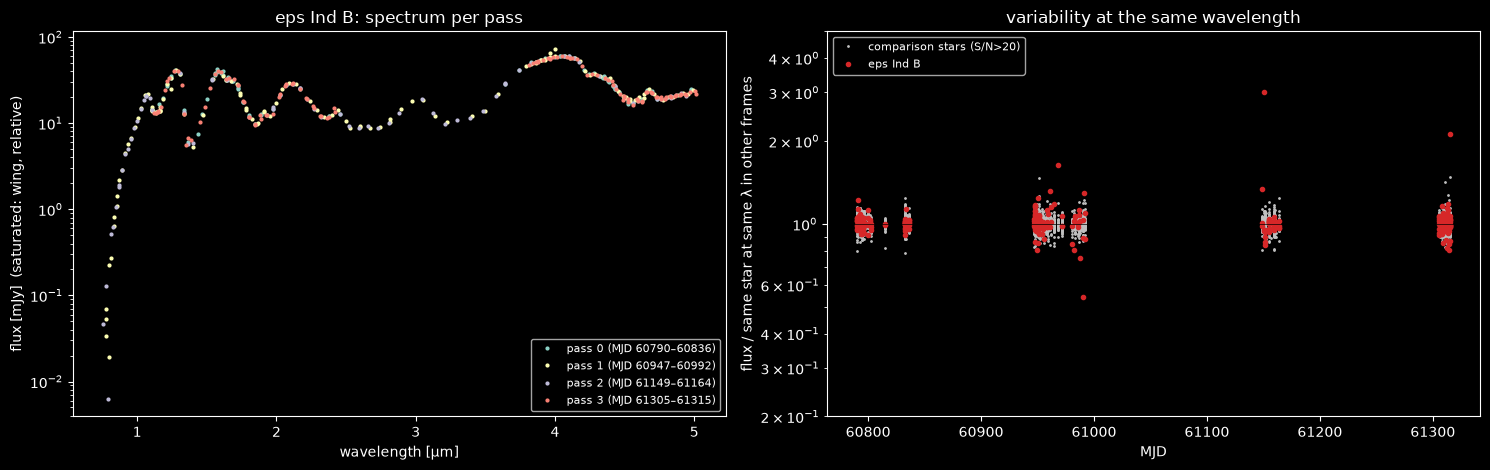

   injected 10.0 % at P =    40 d -> recovered  9.5 %   (Lomb-Scargle best period 40.0 d)
   injected 10.0 % at P =   300 d -> recovered 12.5 %   (Lomb-Scargle best period 304.6 d)
   injected  5.0 % at P =    40 d -> recovered  4.5 %   (Lomb-Scargle best period 40.0 d)
   injected  0.0 % at P =    40 d -> recovered  1.2 %   (Lomb-Scargle best period 5.0 d)


In [7]:
def by_band(d):
    """Median residual per pass in each SPHEREx band: shows if the change depends on wavelength."""
    tg = d[d["src"] == 0]
    bands = [(0.75, 1.10), (1.10, 1.65), (1.65, 2.40), (2.40, 3.80), (3.80, 5.00)]
    passes = np.unique(tg["pass_id"])
    print("   band [µm]   " + "  ".join(f"pass {p:<6}" for p in passes))
    for lo, hi in bands:
        cells = []
        for p in passes:
            c = np.array(tg["resid"][(tg["pass_id"] == p) & (tg["lambda_um"] >= lo) & (tg["lambda_um"] < hi)])
            c = c[np.isfinite(c)]
            cells.append(f"{np.median(c):5.2f} ({len(c):3d})" if len(c) >= 3 else "    -      ")
        print(f"   {lo:.2f}-{hi:.2f}   " + "  ".join(cells))


def best_period(d, which="target"):
    k = (d["src"] == 0) if which == "target" else (d["src"] > 0) & (d["flux_mjy"] > MIN_COMP_SNR * d["err_bkg_mjy"])
    g = d[k & np.isfinite(d["resid"])]
    r = np.array(g["resid"]); ok = np.abs(r - np.median(r)) < 5 * robust_std(r)
    freq, power = LombScargle(np.array(g["mjd"])[ok], r[ok]).autopower(minimum_frequency=1 / 1000, maximum_frequency=1 / 2)
    print(f"   {which}: Lomb-Scargle best period {1 / freq[np.argmax(power)]:.1f} d, power {power.max():.2f} "
          f"(time span {g['mjd'].max() - g['mjd'].min():.0f} d)")


def analyze(name, inject=False):
    star = resolve(name)
    t = find_frames(star)
    print(f"{name}: {len(t)} frames, frames per pass {np.bincount(t['pass_id'])}")
    cache = DATA_DIR / f"{re.sub(r'\W+', '_', name).lower()}_variability.ecsv"
    if cache.exists():
        m = Table.read(cache)
    else:
        comps = find_comparisons(t, star)
        print(f"{len(comps)} comparison stars")
        m = measure_all(t, star, comps)
        m.write(cache, overwrite=True)
    valid = np.isfinite(m["flux_mjy"][m["src"] == 0]).mean()
    if valid < 0.2:
        print(f"   only {100 * valid:.0f} % of the target apertures are usable (saturated) -> PSF-wing photometry")
        m = use_wings(m)
    d = residuals(m)
    summary(d, name)
    by_band(d)
    best_period(d, "target")
    best_period(d, "comparison stars")
    plot(d, name)
    if inject:
        for amp, period_d in [(0.10, 40), (0.10, 300), (0.05, 40), (0.0, 40)]:
            inject_and_recover(m, amp, period_d)
    return d


d_eps = analyze("eps Ind B", inject=True)     # control: constant star + injection test


RW Aur: 335 frames, frames per pass [112 114 109]
40 comparison stars
335 frames, 0 unreadable, 13252 measurements in 71 s

== RW Aur: 95 target measurements with a same-λ reference, 40 comparison stars
   scatter: target 34.1 %   |   comparison stars (S/N>20) 2.7 %
   frame zero point: scatter 1.10 %, expected from noise 0.63 % -> real calibration error ~0.91 % per frame (335 frames, 30 stars each)
   pass 0: target 0.782 ± 0.045 (n=29)   comparison stars 1.003
   pass 1: target 0.992 ± 0.034 (n=36)   comparison stars 0.995
   pass 2: target 1.209 ± 0.121 (n=30)   comparison stars 1.003
   band [µm]   pass 0       pass 1       pass 2     
   0.75-1.10    0.73 ( 16)   0.96 ( 17)   1.49 ( 15)
   1.10-1.65    0.75 (  4)   0.96 (  5)   1.24 (  3)
   1.65-2.40       -            -            -      
   2.40-3.80       -            -            -      
   3.80-5.00    1.50 (  5)   1.11 ( 11)   0.70 ( 10)
   target: Lomb-Scargle best period 18.0 d, power 0.33 (time span 380 d)
   comparison 

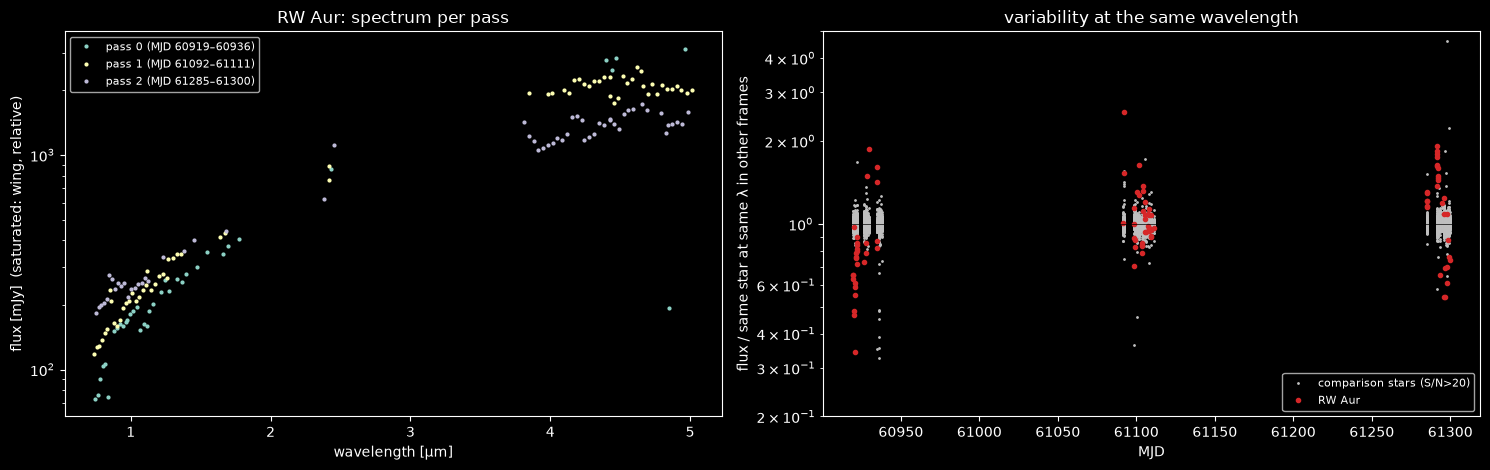

In [8]:
d_rw = analyze("RW Aur")


R Dra: 2424 frames, frames per pass [2424]
18 comparison stars
2424 frames, 0 unreadable, 44089 measurements in 485 s
   only 0 % of the target apertures are usable (saturated) -> PSF-wing photometry

== R Dra: 2370 target measurements with a same-λ reference, 18 comparison stars
   scatter: target 25.1 %   |   comparison stars (S/N>20) 2.5 %
   frame zero point: scatter 0.92 %, expected from noise 0.85 % -> real calibration error ~0.35 % per frame (2163 frames, 14 stars each)
   pass 0: target 1.000 ± 0.006 (n=2370)   comparison stars 1.000
   band [µm]   pass 0     
   0.75-1.10    0.99 (521)
   1.10-1.65    0.97 (106)
   1.65-2.40    1.02 (527)
   2.40-3.80    1.00 (562)
   3.80-5.00    1.00 (634)
   target: Lomb-Scargle best period 244.8 d, power 0.31 (time span 519 d)
   comparison stars: Lomb-Scargle best period 38.4 d, power 0.00 (time span 519 d)


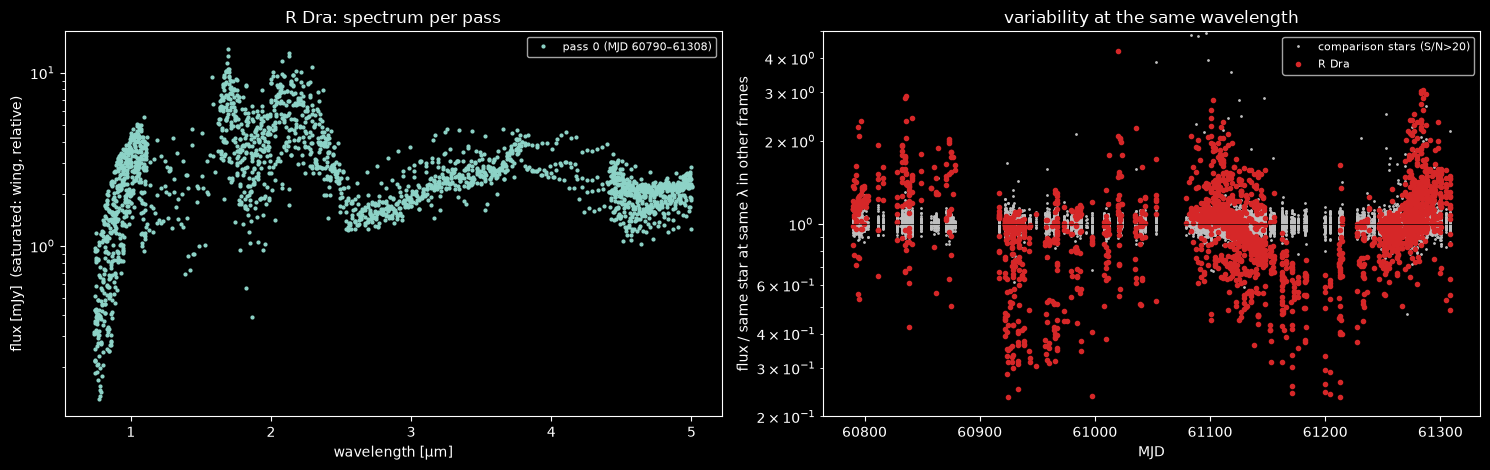

In [9]:
d_rdra = analyze("R Dra")      # ~9 min the first time (2424 frames)


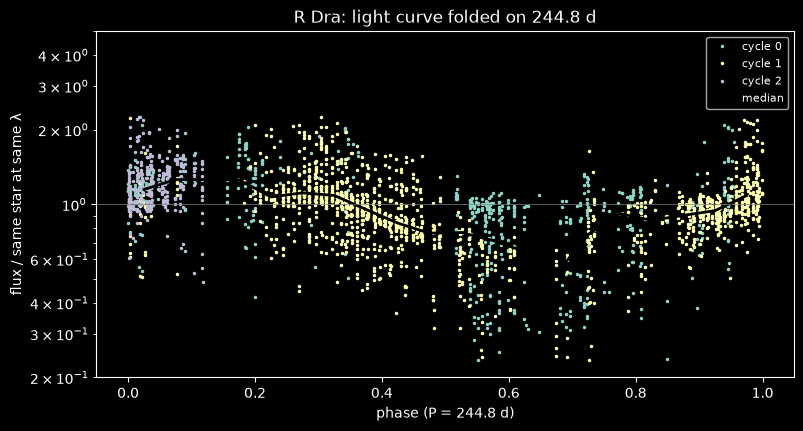

   folded on P = 244.8 d: binned median goes from 0.52 to 1.26 (peak-to-peak x2.4)


In [10]:
def phase_fold(d, name, period_d=None):
    """Fold the target's same-λ residuals on its best period, coloured by cycle, plus the binned median."""
    tg = d[(d["src"] == 0) & np.isfinite(d["resid"])]
    r = np.array(tg["resid"]); ok = np.abs(r - np.median(r)) < 5 * robust_std(r)
    mjd = np.array(tg["mjd"])[ok]; r = r[ok]
    if period_d is None:
        freq, power = LombScargle(mjd, r).autopower(minimum_frequency=1 / 1000, maximum_frequency=1 / 2)
        period_d = 1 / freq[np.argmax(power)]
    phase = ((mjd - mjd.min()) / period_d) % 1
    cycle = ((mjd - mjd.min()) // period_d).astype(int)
    bins = np.linspace(0, 1, 21)
    med = [np.median(r[(phase >= a) & (phase < b)]) if np.any((phase >= a) & (phase < b)) else np.nan
           for a, b in zip(bins[:-1], bins[1:])]
    fig, ax = plt.subplots(figsize=(9, 4.5))
    for c in np.unique(cycle):
        ax.plot(phase[cycle == c], r[cycle == c], ".", ms=3, label=f"cycle {c}")
    ax.plot(0.5 * (bins[:-1] + bins[1:]), med, "k-", lw=2, label="median")
    ax.axhline(1, color="0.5", lw=0.5)
    ax.set_yscale("log"); ax.set_ylim(0.2, 5)
    ax.set_xlabel(f"phase (P = {period_d:.1f} d)"); ax.set_ylabel("flux / same star at same λ")
    ax.set_title(f"{name}: light curve folded on {period_d:.1f} d"); ax.legend(fontsize=8)
    plt.show()
    print(f"   folded on P = {period_d:.1f} d: binned median goes from {np.nanmin(med):.2f} to {np.nanmax(med):.2f} "
          f"(peak-to-peak x{np.nanmax(med) / np.nanmin(med):.1f})")


phase_fold(d_rdra, "R Dra")


   target residuals: 95 from the aperture, 228 from the wings

== RW Aur (aperture + wings): 323 target measurements with a same-λ reference, 40 comparison stars
   scatter: target 36.2 %   |   comparison stars (S/N>20) 2.7 %
   frame zero point: scatter 1.10 %, expected from noise 0.63 % -> real calibration error ~0.91 % per frame (335 frames, 30 stars each)
   pass 0: target 1.053 ± 0.061 (n=107)   comparison stars 1.003
   pass 1: target 1.037 ± 0.023 (n=108)   comparison stars 0.995
   pass 2: target 0.795 ± 0.043 (n=108)   comparison stars 1.003
   band [µm]   pass 0       pass 1       pass 2     
   0.75-1.10    0.76 ( 17)   0.96 ( 17)   1.49 ( 17)
   1.10-1.65    0.78 ( 19)   1.11 ( 19)   1.13 ( 20)
   1.65-2.40    1.00 ( 17)   1.14 ( 17)   0.89 ( 17)
   2.40-3.80    1.05 ( 19)   1.04 ( 19)   0.79 ( 18)
   3.80-5.00    1.57 ( 34)   1.01 ( 36)   0.61 ( 36)


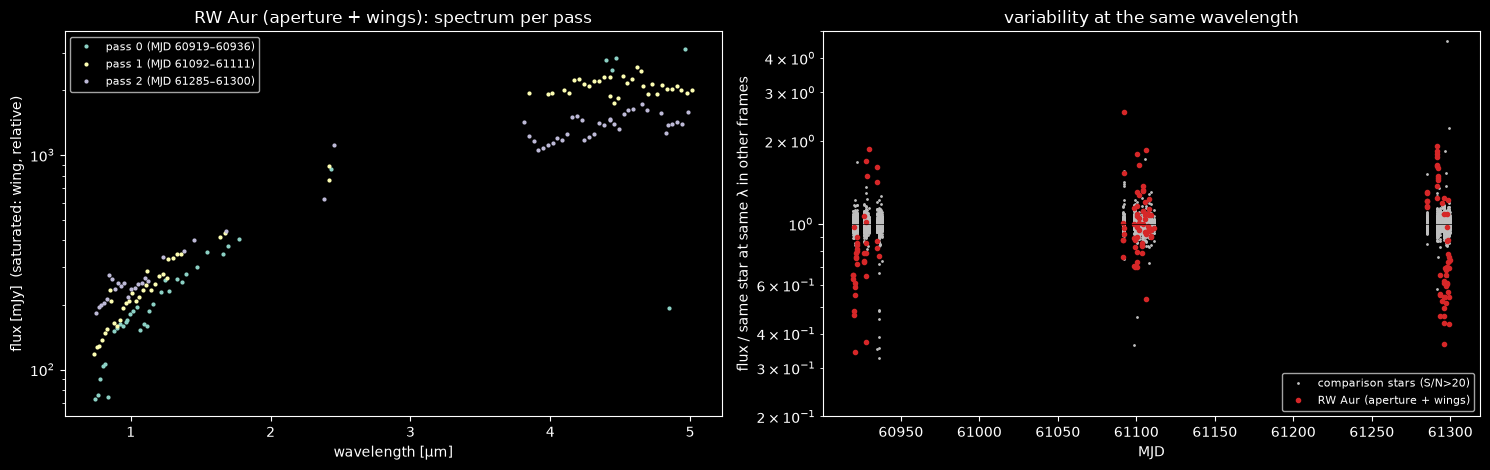

In [11]:
def hybrid_residuals(m):
    """Target partly saturated: use the aperture where it is usable and the PSF wings elsewhere.
    Both are turned into same-λ residuals first, so their different units cancel."""
    ap = residuals(m)
    wg = residuals(use_wings(m))
    k = ap["src"] == 0
    use_wing = k & ~np.isfinite(ap["resid"]) & np.isfinite(wg["resid"])
    ap["resid"][use_wing] = wg["resid"][use_wing]
    ap["method"] = np.where(use_wing, "wing", np.where(k & np.isfinite(ap["resid"]), "aperture", ""))
    print(f"   target residuals: {np.sum(ap['method'] == 'aperture')} from the aperture, "
          f"{np.sum(ap['method'] == 'wing')} from the wings")
    return ap


m_rw = Table.read(DATA_DIR / "rw_aur_variability.ecsv")
d_rw2 = hybrid_residuals(m_rw)
summary(d_rw2, "RW Aur (aperture + wings)")
by_band(d_rw2)
plot(d_rw2, "RW Aur (aperture + wings)")



Barnard's star: 358 frames, frames per pass [118 121 119]
40 comparison stars
358 frames, 0 unreadable, 14064 measurements in 69 s
   only 1 % of the target apertures are usable (saturated) -> PSF-wing photometry

== Barnard's star: 350 target measurements with a same-λ reference, 40 comparison stars
   scatter: target 10.1 %   |   comparison stars (S/N>20) 2.7 %
   frame zero point: scatter 0.78 %, expected from noise 0.59 % -> real calibration error ~0.51 % per frame (355 frames, 33 stars each)
   pass 0: target 0.974 ± 0.010 (n=116)   comparison stars 1.001
   pass 1: target 1.001 ± 0.013 (n=118)   comparison stars 1.001
   pass 2: target 1.017 ± 0.011 (n=116)   comparison stars 0.999
   band [µm]   pass 0       pass 1       pass 2     
   0.75-1.10    0.98 ( 21)   1.03 ( 17)   1.01 ( 17)
   1.10-1.65    0.88 ( 20)   0.83 ( 18)   1.27 ( 23)
   1.65-2.40    0.82 ( 16)   0.98 ( 22)   1.11 ( 17)
   2.40-3.80    0.99 ( 24)   1.03 ( 19)   0.99 ( 18)
   3.80-5.00    0.99 ( 33)   1.01 ( 41

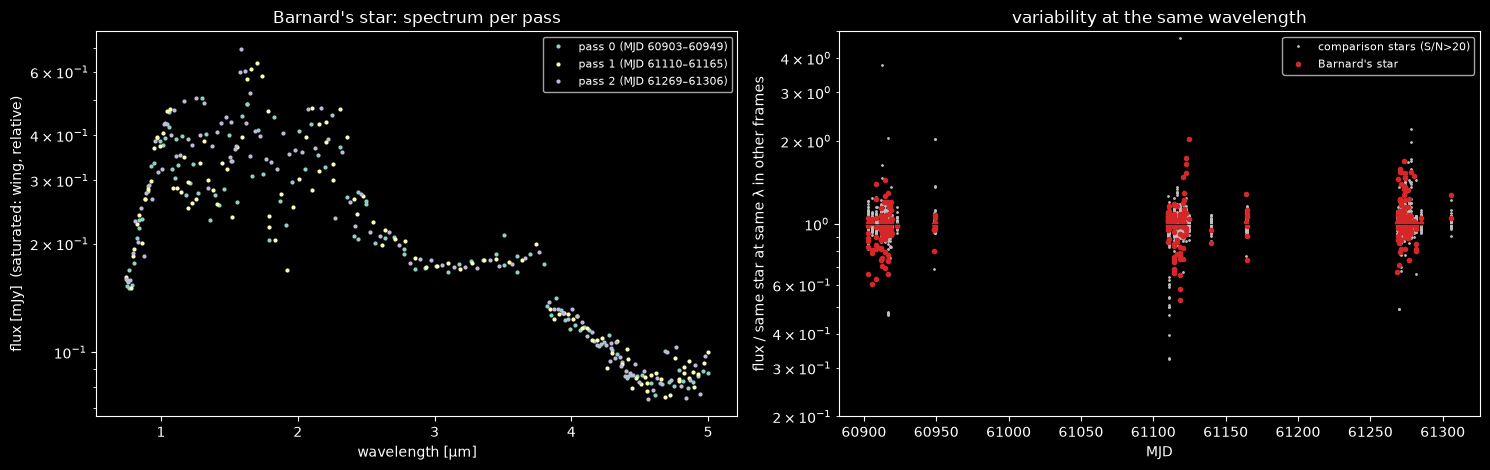

In [12]:
d_barnard = analyze("Barnard's star")


WISE J085510.83-071442.5: 258 frames, frames per pass [ 30 128 100]
26 comparison stars
258 frames, 0 unreadable, 6801 measurements in 61 s

== WISE J085510.83-071442.5: 139 target measurements with a same-λ reference, 26 comparison stars
   scatter: target 22.1 %   |   comparison stars (S/N>20) 3.6 %
   frame zero point: scatter 1.27 %, expected from noise 1.41 % -> real calibration error ~0.00 % per frame (176 frames, 10 stars each)
   pass 0: target 0.763 ± 0.065 (n=17)   comparison stars 1.002
   pass 1: target 0.992 ± 0.032 (n=67)   comparison stars 1.002
   pass 2: target 1.036 ± 0.034 (n=55)   comparison stars 0.997
   band [µm]   pass 0       pass 1       pass 2     
   0.75-1.10       -            -         0.99 (  3)
   1.10-1.65    0.76 (  7)   1.01 ( 20)   1.08 ( 10)
   1.65-2.40       -         0.95 ( 14)   1.08 ( 15)
   2.40-3.80       -            -         1.06 (  3)
   3.80-5.00    0.80 (  8)   1.09 ( 30)   0.92 ( 24)
   target: Lomb-Scargle best period 4.6 d, power 0.

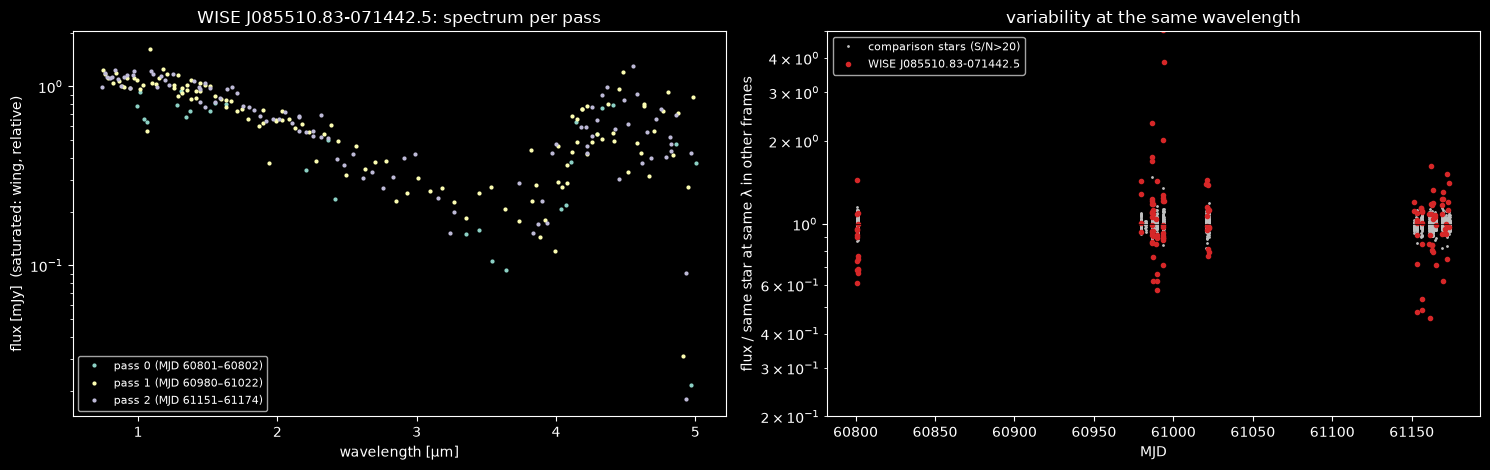

In [13]:
d_wise = analyze("WISE J085510.83-071442.5")
